In [1]:
import numpy as np
import time
import torch
import matplotlib.pyplot as plt
plt.rc('text', usetex=False)
import multiprocessing as mp
from typing import Union


from abc import ABC
from epde.preprocessing.cheb import process_point_cheb

from epde.preprocessing.deriv_calculators import Heatmap, AbstractDeriv, AdaptiveFiniteDeriv, PolynomialDeriv, SpectralDeriv, TotalVariation


Mean Squared Error (MSE) for noise level 0:
  u_xxx: 0.005009410231279766
  u_x: 4.902244150115467e-05
  u_t: 0.00043608448757878246
Mean Squared Error (MSE) for noise level 0.005:
  u_xxx: 0.016957455226173177
  u_x: 0.00012803751669296614
  u_t: 0.004898349060413172
Mean Squared Error (MSE) for noise level 0.01:
  u_xxx: 0.05015288971914194
  u_x: 0.00036576749590229457
  u_t: 0.018687342193926315


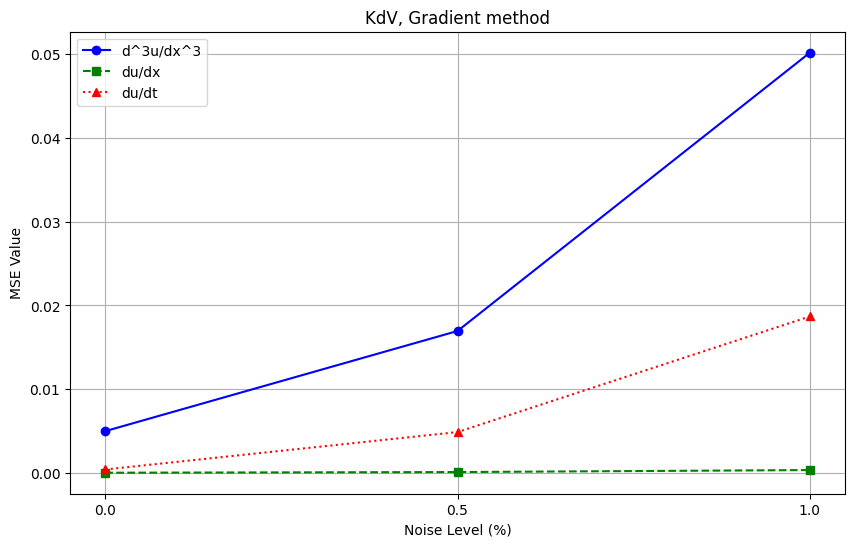

In [6]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xxx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xxx = np.load(f'data_kdv_noise{noise}_u_xxx.npy')
    u_x = np.load(f'data_kdv_noise{noise}_u_x.npy')
    u_t = np.load(f'data_kdv_noise{noise}_u_t.npy')
    
    gradient_xxx = np.load(f'kdv_Gradient_xxx_noise{noise}.npy')
    gradient_x = np.load(f'kdv_Gradient_x_noise{noise}.npy')
    gradient_t = np.load(f'kdv_Gradient_t_noise{noise}.npy')

    u_xxx = u_xxx[5:27, 5:27]
    u_x = u_x[5:27, 5:27]
    u_t = u_t[5:27, 5:27]
    
    gradient_xxx = gradient_xxx[5:27, 5:27]
    gradient_x = gradient_x[5:27, 5:27]
    gradient_t = gradient_t[5:27, 5:27]    
     
    # Вычисление MSE для каждого случая
    mse_u_xxx = calculate_mse(u_xxx, gradient_xxx)
    mse_u_x = calculate_mse(u_x, gradient_x)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_xxx.append(mse_u_xxx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xxx: {mse_u_xxx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xxx, marker='o', linestyle='-', color='b', label='d^3u/dx^3')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('KdV, Gradient method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('kdv_Gradient_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xxx: 0.012066028998828637
  u_x: 5.713169547205552e-05
  u_t: 8.132512340138074e-07
Mean Squared Error (MSE) for noise level 0.005:
  u_xxx: 0.022077349425749772
  u_x: 0.0001298123650662784
  u_t: 0.004131744472967321
Mean Squared Error (MSE) for noise level 0.01:
  u_xxx: 0.049536531365247126
  u_x: 0.0003496515962150434
  u_t: 0.017121456557264332


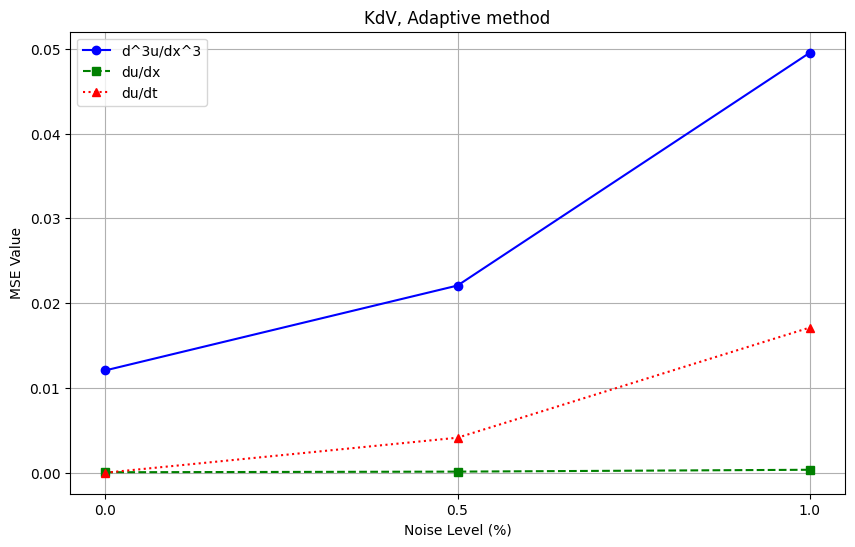

In [9]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xxx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xxx = np.load(f'data_kdv_noise{noise}_u_xxx.npy')
    u_x = np.load(f'data_kdv_noise{noise}_u_x.npy')
    u_t = np.load(f'data_kdv_noise{noise}_u_t.npy')
    
    gradient_xxx = np.load(f'kdv_Adaptive_xxx_noise{noise}.npy')
    gradient_x = np.load(f'kdv_Adaptive_x_noise{noise}.npy')
    gradient_t = np.load(f'kdv_Adaptive_t_noise{noise}.npy')
    
    u_xxx = u_xxx[5:27, 5:27]
    u_x = u_x[5:27, 5:27]
    u_t = u_t[5:27, 5:27]
    
    gradient_xxx = gradient_xxx[5:27, 5:27]
    gradient_x = gradient_x[5:27, 5:27]
    gradient_t = gradient_t[5:27, 5:27]  
        
    # Вычисление MSE для каждого случая
    mse_u_xxx = calculate_mse(u_xxx, gradient_xxx)
    mse_u_x = calculate_mse(u_x, gradient_x)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_xxx.append(mse_u_xxx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xxx: {mse_u_xxx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xxx, marker='o', linestyle='-', color='b', label='d^3u/dx^3')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('KdV, Adaptive method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('kdv_Adaptive_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xxx: 0.035051794245578895
  u_x: 0.0006083780637522261
  u_t: 9.353576020947893e-06
Mean Squared Error (MSE) for noise level 0.005:
  u_xxx: 0.03662103777255222
  u_x: 0.0006259598717690175
  u_t: 0.0009162802001064294
Mean Squared Error (MSE) for noise level 0.01:
  u_xxx: 0.038984202635129424
  u_x: 0.0006782371509541426
  u_t: 0.0034494829697085793


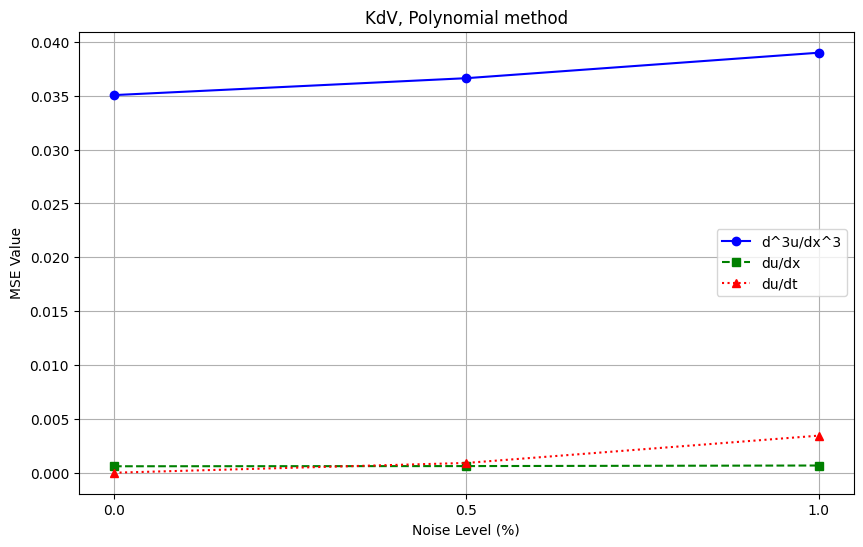

In [10]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xxx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xxx = np.load(f'data_kdv_noise{noise}_u_xxx.npy')
    u_x = np.load(f'data_kdv_noise{noise}_u_x.npy')
    u_t = np.load(f'data_kdv_noise{noise}_u_t.npy')
    
    gradient_xxx = np.load(f'kdv_Polynomial_xxx_noise{noise}.npy')
    gradient_x = np.load(f'kdv_Polynomial_x_noise{noise}.npy')
    gradient_t = np.load(f'kdv_Polynomial_t_noise{noise}.npy')

    u_xxx = u_xxx[5:27, 5:27]
    u_x = u_x[5:27, 5:27]
    u_t = u_t[5:27, 5:27]
    
    gradient_xxx = gradient_xxx[5:27, 5:27]
    gradient_x = gradient_x[5:27, 5:27]
    gradient_t = gradient_t[5:27, 5:27]  
        
    # Вычисление MSE для каждого случая
    mse_u_xxx = calculate_mse(u_xxx, gradient_xxx)
    mse_u_x = calculate_mse(u_x, gradient_x)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_xxx.append(mse_u_xxx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xxx: {mse_u_xxx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xxx, marker='o', linestyle='-', color='b', label='d^3u/dx^3')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('KdV, Polynomial method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('kdv_Polynomial_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xxx: 14.191017369306326
  u_x: 0.015494114462768202
  u_t: 0.09335828966380241
Mean Squared Error (MSE) for noise level 0.005:
  u_xxx: 14.196614290312317
  u_x: 0.015471591409653238
  u_t: 0.09336699284830306
Mean Squared Error (MSE) for noise level 0.01:
  u_xxx: 14.227053859444105
  u_x: 0.015448015895116286
  u_t: 0.09407316065555578


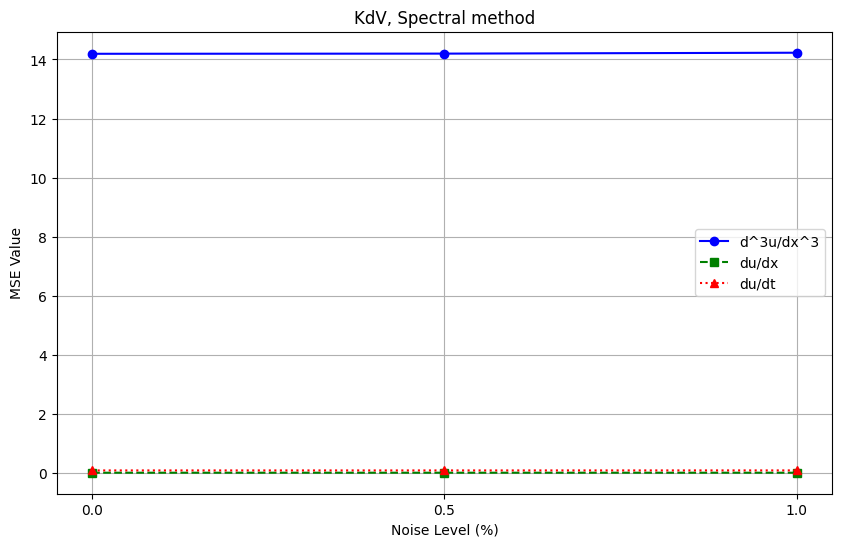

In [16]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xxx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xxx = np.load(f'data_kdv_noise{noise}_u_xxx.npy')
    u_x = np.load(f'data_kdv_noise{noise}_u_x.npy')
    u_t = np.load(f'data_kdv_noise{noise}_u_t.npy')
    
    gradient_xxx = np.load(f'kdv_Spectral_xxx_noise{noise}.npy')
    gradient_x = np.load(f'kdv_Spectral_x_noise{noise}.npy')
    gradient_t = np.load(f'kdv_Spectral_t_noise{noise}.npy')

    u_xxx = u_xxx[5:27, 5:27]
    u_x = u_x[5:27, 5:27]
    u_t = u_t[5:27, 5:27]
    
    gradient_xxx = gradient_xxx[5:27, 5:27]
    gradient_x = gradient_x[5:27, 5:27]
    gradient_t = gradient_t[5:27, 5:27]
      
    # Вычисление MSE для каждого случая
    mse_u_xxx = calculate_mse(u_xxx, gradient_xxx)
    mse_u_x = calculate_mse(u_x, gradient_x)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_xxx.append(mse_u_xxx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xxx: {mse_u_xxx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xxx, marker='o', linestyle='-', color='b', label='d^3u/dx^3')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('KdV, Spectral method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('kdv_Spectral_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xxx: 0.46014053884844114
  u_x: 0.06379935889850095
  u_t: 0.41956907500760426
Mean Squared Error (MSE) for noise level 0.005:
  u_xxx: 0.46165669097110945
  u_x: 0.06378202646113634
  u_t: 0.4195191425993907
Mean Squared Error (MSE) for noise level 0.01:
  u_xxx: 0.4930821768933489
  u_x: 0.06376880864651985
  u_t: 0.4197744075913535


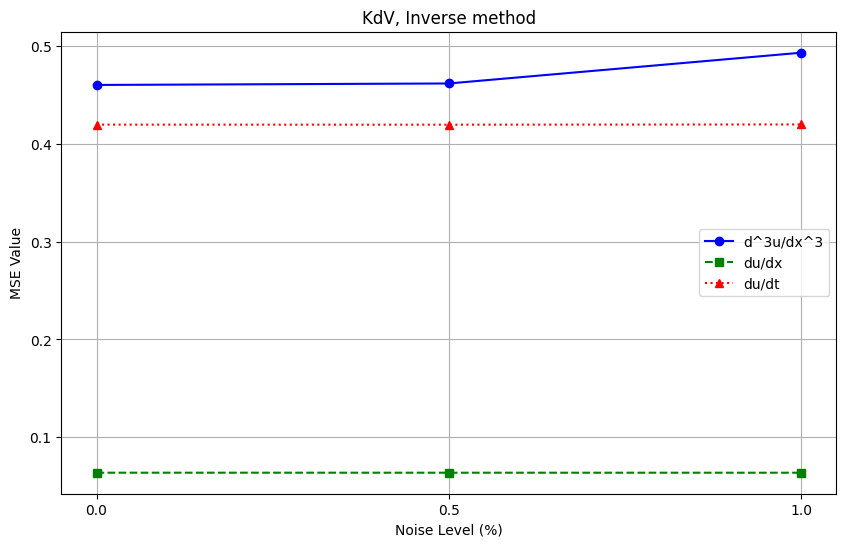

In [18]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xxx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xxx = np.load(f'data_kdv_noise{noise}_u_xxx.npy')
    u_x = np.load(f'data_kdv_noise{noise}_u_x.npy')
    u_t = np.load(f'data_kdv_noise{noise}_u_t.npy')
    
    gradient_xxx = np.load(f'kdv_Inverse_xxx_noise{noise}.npy')
    gradient_x = np.load(f'kdv_Inverse_x_noise{noise}.npy')
    gradient_t = np.load(f'kdv_Inverse_t_noise{noise}.npy')

    u_xxx = u_xxx[5:27, 5:27]
    u_x = u_x[5:27, 5:27]
    u_t = u_t[5:27, 5:27]
    
    gradient_xxx = gradient_xxx[5:27, 5:27]
    gradient_x = gradient_x[5:27, 5:27]
    gradient_t = gradient_t[5:27, 5:27]
       
    # Вычисление MSE для каждого случая
    mse_u_xxx = calculate_mse(u_xxx, gradient_xxx)
    mse_u_x = calculate_mse(u_x, gradient_x)
    mse_u_t = calculate_mse(u_t, gradient_t)
    
    mse_values_u_xxx.append(mse_u_xxx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xxx: {mse_u_xxx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xxx, marker='o', linestyle='-', color='b', label='d^3u/dx^3')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('KdV, Inverse method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('kdv_Inverse_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xxx: 0.32750713769489903
  u_x: 0.09371403253270225
  u_t: 0.3569583551271306
Mean Squared Error (MSE) for noise level 0.005:
  u_xxx: 0.3275021536141888
  u_x: 0.09370493435266508
  u_t: 0.3570571256105288
Mean Squared Error (MSE) for noise level 0.01:
  u_xxx: 0.32728584362789037
  u_x: 0.09363516539375873
  u_t: 0.3572689125570128


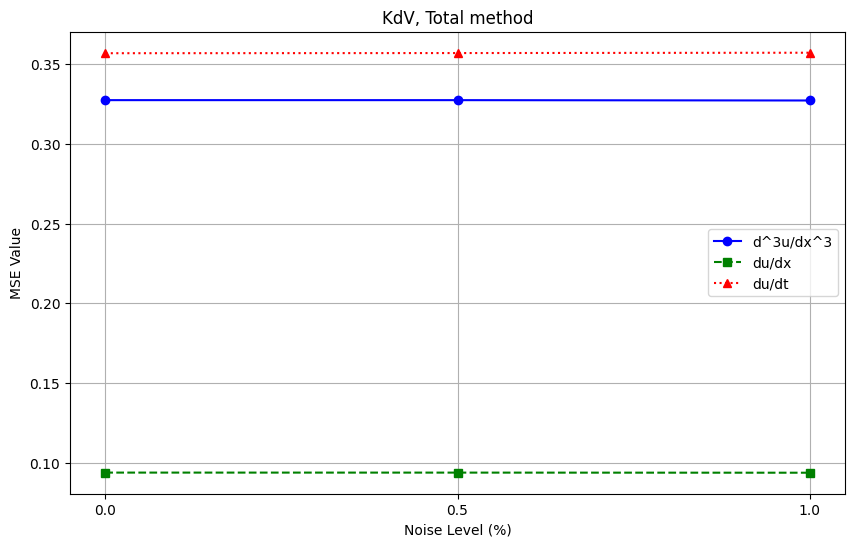

In [23]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xxx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xxx = np.load(f'data_kdv_noise{noise}_u_xxx.npy')
    u_x = np.load(f'data_kdv_noise{noise}_u_x.npy')
    u_t = np.load(f'data_kdv_noise{noise}_u_t.npy')
    
    gradient_xxx = np.load(f'kdv_Total_xxx_noise{noise}.npy')
    gradient_x = np.load(f'kdv_Total_x_noise{noise}.npy')
    gradient_t = np.load(f'kdv_Total_t_noise{noise}.npy')
    
    # Вычисление MSE для каждого случая
    mse_u_xxx = calculate_mse(u_xxx, gradient_xxx)
    mse_u_x = calculate_mse(u_x, gradient_x)
    mse_u_t = calculate_mse(u_t, gradient_t)

    u_xxx = u_xxx[5:27, 5:27]
    u_x = u_x[5:27, 5:27]
    u_t = u_t[5:27, 5:27]
    
    gradient_xxx = gradient_xxx[5:27, 5:27]
    gradient_x = gradient_x[5:27, 5:27]
    gradient_t = gradient_t[5:27, 5:27]
        
    mse_values_u_xxx.append(mse_u_xxx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xxx: {mse_u_xxx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xxx, marker='o', linestyle='-', color='b', label='d^3u/dx^3')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('KdV, Total method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('kdv_Total_error.pdf', format='pdf')
plt.show()
